<center><h1>Case_John_HW5</h1></center>
<br>
<br>

Name: John Case
<br>
Github Username: johncase17
<br>
USC ID: 2249212508

## 1. Decision Trees as Interpretable Models

Import packages

In [253]:
%%capture
%pip install -r ../requirements.txt
from sklearn.model_selection import GridSearchCV
import pandas as pd
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.model_selection import KFold
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [81]:
diagnosis_path = '../data/diagnosis.csv'
features_names = ['temp', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pain', 'urethra_discomfort']
accute_data = pd.read_csv(diagnosis_path, sep='\t', decimal=',', encoding='utf-16', header=None)
accute_data = accute_data.replace({'no': 0, 'yes': 1})
accute_data[0] = accute_data[0].astype(float)
for col in accute_data.columns:
    if col >= 1:
        accute_data[col] = accute_data[col].astype(int)


inflamation = accute_data[6].copy()
nephriti = accute_data[7].copy()
combined_predict = ["empty"]*len(accute_data)
for i in range(len(inflamation)):
    if inflamation[i] == 1 and nephriti[i] == 1:
        combined_predict[i] = "inflamation and nephriti"
    elif inflamation[i] == 1 and nephriti[i] == 0:
        combined_predict[i] = "inflamation"
    elif inflamation[i] == 0 and nephriti[i] == 1:
        combined_predict[i] = "nephriti"
    else:
        combined_predict[i] = "none"
accute_data = accute_data.drop(accute_data.columns[[6, 7]], axis=1)
accute_data.columns = features_names
#print(accute_data.head())
#print(combined_predict)


### (b) Build a decision tree

['inflamation' 'inflamation and nephriti' 'nephriti' 'none']


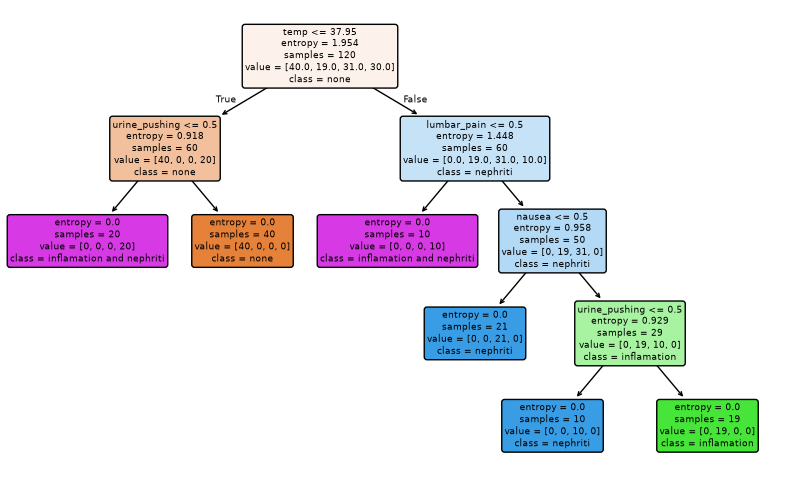

In [87]:
inflamation_dt = tree.DecisionTreeClassifier(criterion='entropy', max_depth=5)
inflamation_dt.fit(accute_data, combined_predict)
print(inflamation_dt.classes_)
plt.figure(figsize=(10, 6))
names = list(dict.fromkeys(combined_predict))
plot_tree(inflamation_dt, filled=True, rounded=True, feature_names=features_names, class_names=names)
plt.show()

### (c) Convert the decision rules

In [108]:
#Snippet taken from https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html
def tree_to_code(tree, feature_names):
	"""
	Outputs a decision tree model as a Python function

	Parameters:
	-----------
	tree: decision tree model
		The decision tree to represent as a function
	feature_names: list
		The feature names of the dataset used for building the decision tree
	"""

	tree_ = tree.tree_
	feature_name = feature_names
	print("def tree({}):".format(", ".join(feature_names)))

	def recurse(node, depth):
		indent = "  " * depth
		if tree_.feature[node] != -2:
			name = feature_names[tree_.feature[node]]
			threshold = tree_.threshold[node]
			print("{}if {} <= {}:".format(indent, name, threshold))
			recurse(tree_.children_left[node], depth + 1)
			print("{}else:  # if {} > {}".format(indent, name, threshold))
			recurse(tree_.children_right[node], depth + 1)
		else:
			print("{}return {}".format(indent, tree.classes_[tree_.value[node].argmax()]))

	recurse(0, 1)

tree_to_code(inflamation_dt, features_names)

def tree(temp, nausea, lumbar_pain, urine_pushing, micturition_pain, urethra_discomfort):
  if temp <= 37.95000076293945:
    if urine_pushing <= 0.5:
      return none
    else:  # if urine_pushing > 0.5
      return inflamation
  else:  # if temp > 37.95000076293945
    if lumbar_pain <= 0.5:
      return none
    else:  # if lumbar_pain > 0.5
      if nausea <= 0.5:
        return nephriti
      else:  # if nausea > 0.5
        if urine_pushing <= 0.5:
          return nephriti
        else:  # if urine_pushing > 0.5
          return inflamation and nephriti


### (d) Minimal decision tree

5


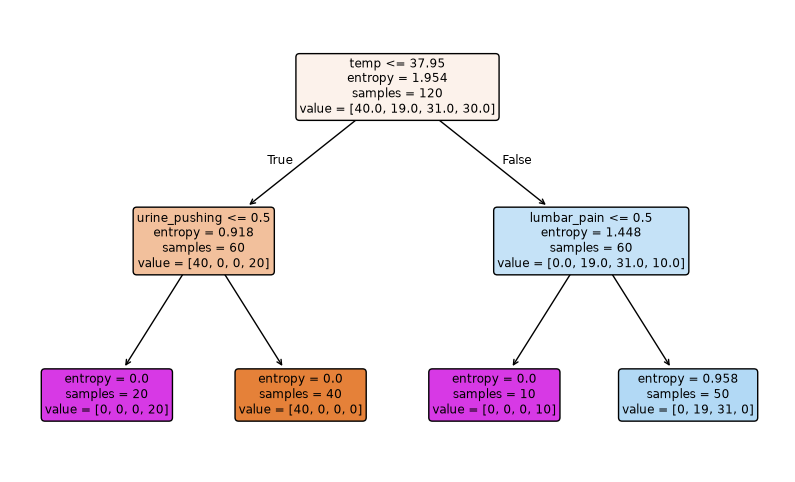

def tree(temp, nausea, lumbar_pain, urine_pushing, micturition_pain, urethra_discomfort):
  if temp <= 37.95000076293945:
    if urine_pushing <= 0.5:
      return none
    else:  # if urine_pushing > 0.5
      return inflamation
  else:  # if temp > 37.95000076293945
    if lumbar_pain <= 0.5:
      return none
    else:  # if lumbar_pain > 0.5
      return nephriti


In [132]:
#reference: https://www.geeksforgeeks.org/machine-learning/pruning-decision-trees/
parameters = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'splitter': ['best', 'random'],
    'max_depth': [1, 2, 3, 4, 5],
    'max_features': ['sqrt', 'log2']
}
tree = DecisionTreeClassifier()
validation = GridSearchCV(estimator=tree, param_grid=parameters)
path = inflamation_dt.cost_complexity_pruning_path(accute_data, combined_predict)
ccp_alphas = path.ccp_alphas
results = []

for value in ccp_alphas:
    temp_model = DecisionTreeClassifier(criterion='entropy', ccp_alpha=value, random_state=42)
    temp_model.fit(accute_data, combined_predict)
    results.append(temp_model)

best_combo = results[0]
for model in results:
    accuracy = model.score(accute_data, combined_predict)
    if accuracy >= 0.8:
        if model.get_depth() < best_combo.get_depth():
            best_combo = model
print(len(ccp_alphas))
plt.figure(figsize=(10, 6))
plot_tree(best_combo, filled=True, rounded=True, feature_names=features_names)
plt.show()
tree_to_code(best_combo, features_names)


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [229]:
communities_path = '../data/communities.csv'
communities_headers = pd.read_csv('../data/communities_headers.csv').columns
communities_data = pd.read_csv(communities_path, na_values='?', header=None)
communities_data.columns = communities_headers
train_data = communities_data.drop(communities_data.index[1494:])
print(communities_data.shape)

(1994, 128)


### (b) Missing values

In [230]:
#impute mean of training values
for col in communities_headers:
    if col != ("communityname"):
        mean = train_data[col].mean()
        communities_data[col] = communities_data[col].fillna(mean)
communities_data = communities_data.drop(['state','county','community','communityname','fold'], axis=1)
test_data = communities_data.drop(communities_data.index[:1495])
train_data = communities_data.drop(communities_data.index[1495:])

### (c) Plot a correlation matrix

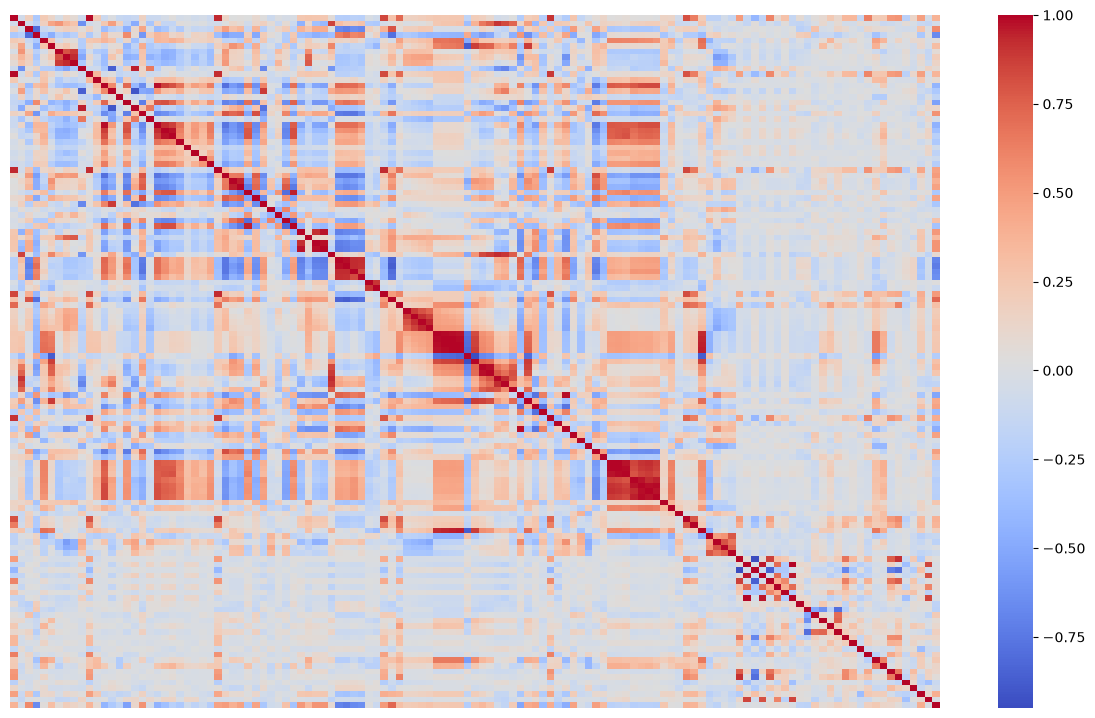

In [224]:
matrix = test_data.corr()
plt.figure(figsize=(15,9))
sns.heatmap(matrix,xticklabels=False, yticklabels=False, cmap="coolwarm")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [225]:
cv_table = pd.DataFrame(np.zeros((len(train_data.columns), 2)), columns=['feature', 'CV'])
temp = 0
cv_table['feature'] = cv_table['feature'].astype(str)
for col in train_data.columns:
    cv_table.loc[temp, 'feature'] = col
    mean = train_data[col].mean()
    std = train_data[col].std()
    cv_table.loc[temp, 'CV'] = std/mean
    temp = temp + 1
print(cv_table.head())

         feature        CV
0     population  2.241105
1  householdsize  0.355800
2   racepctblack  1.428885
3   racePctWhite  0.330213
4   racePctAsian  1.359100


### (e) Scatter plots and box plots for highest CV features

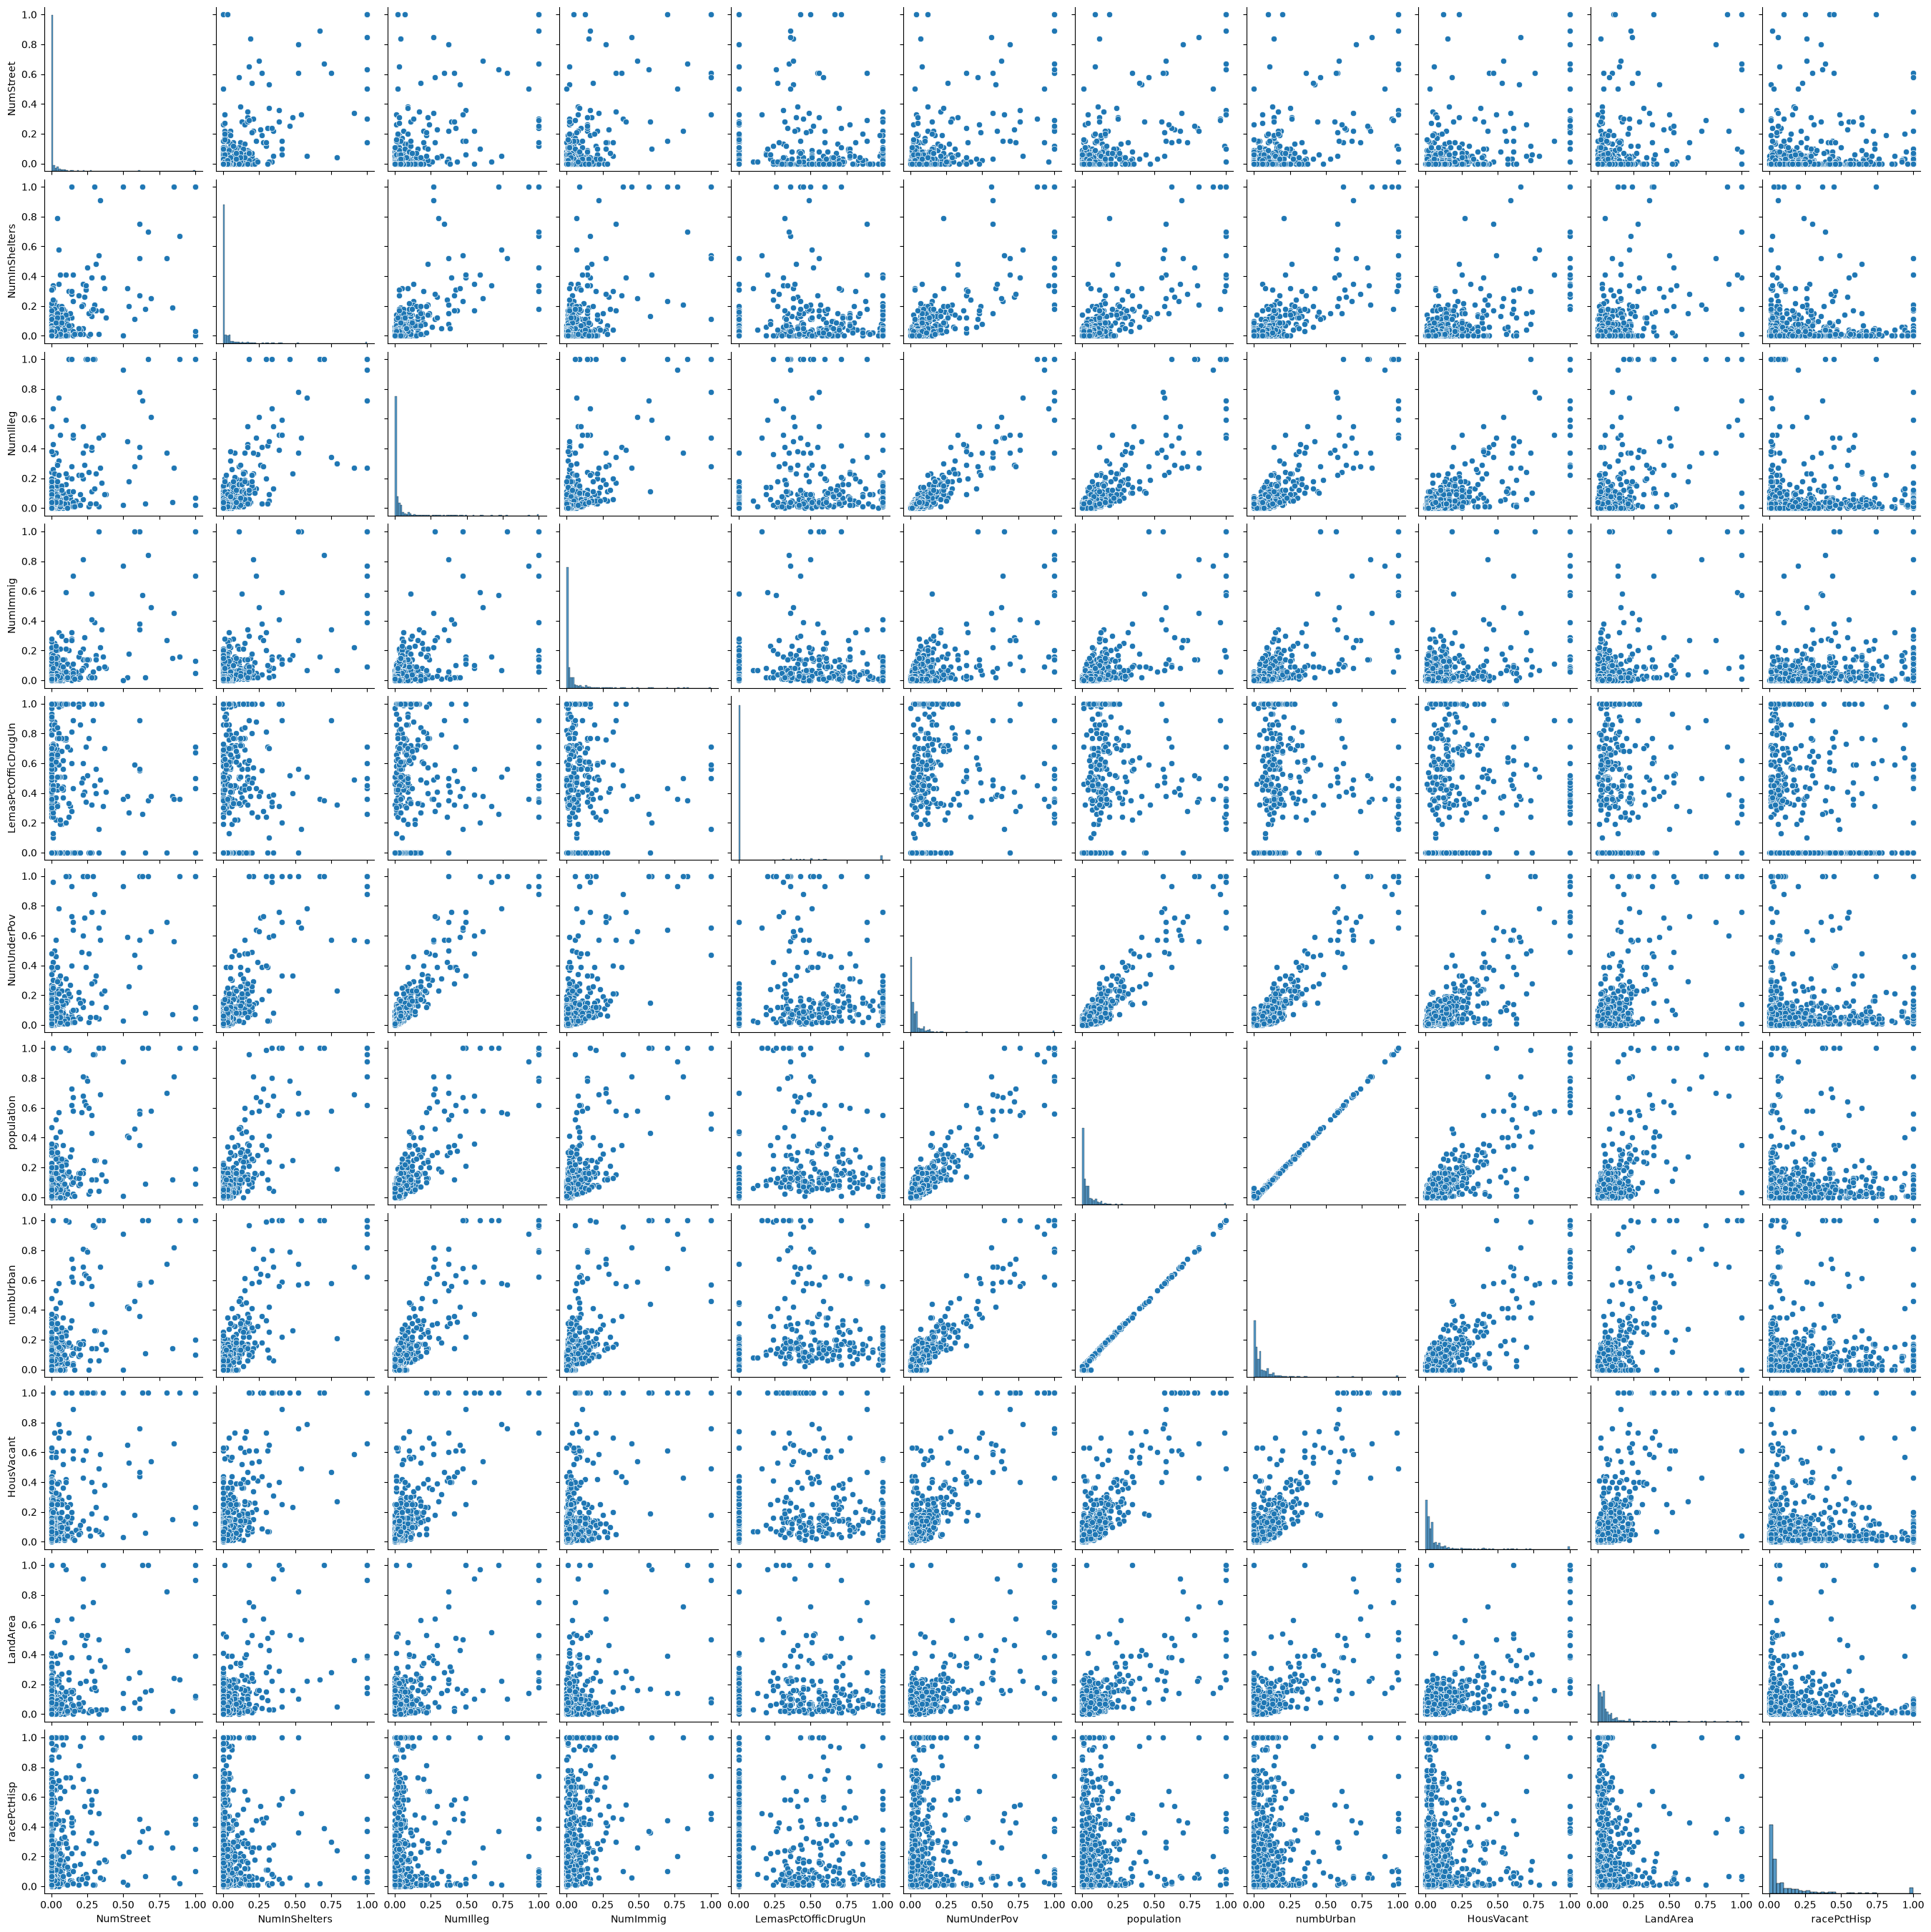

In [226]:
cv_table = cv_table.sort_values(by='CV', ascending=False)
top_features = cv_table['feature'][:11].tolist()
best_train = train_data[top_features]

sns.pairplot(best_train)



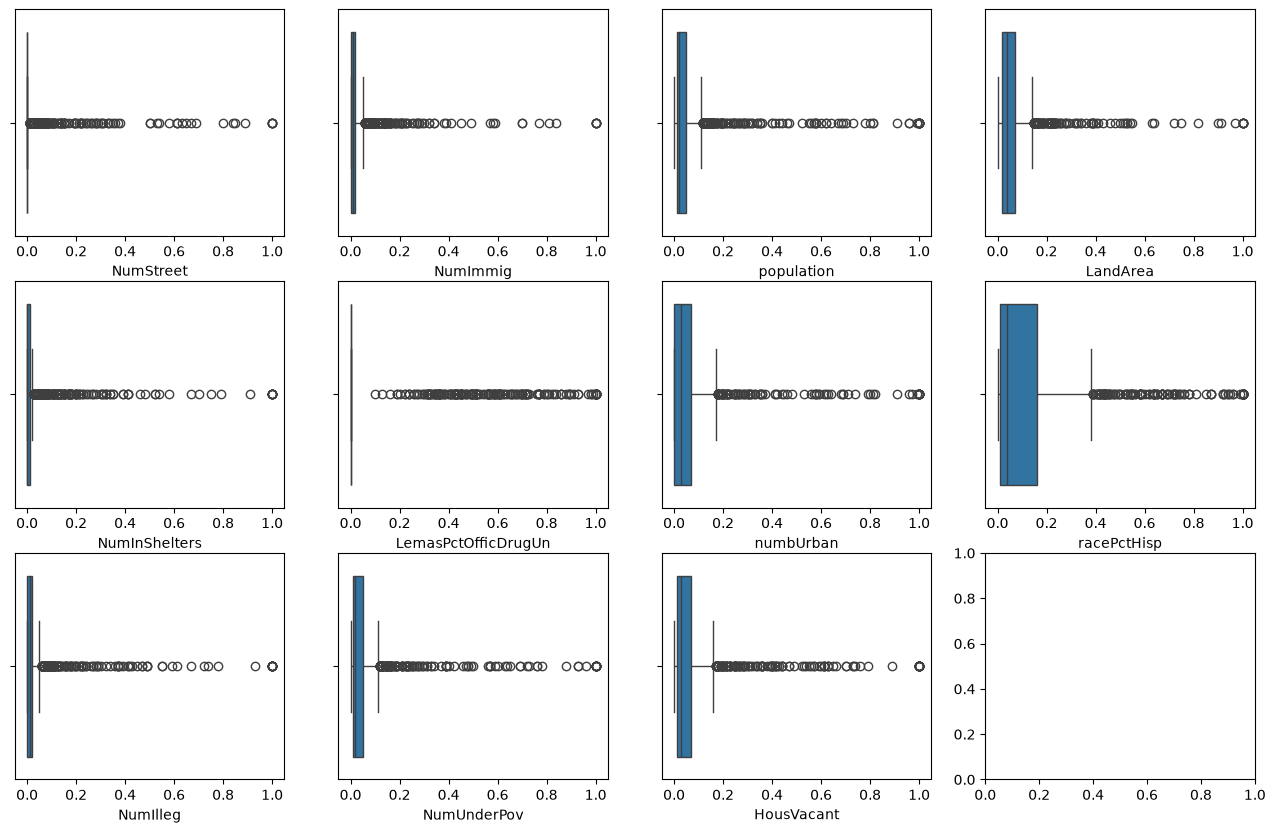

<Figure size 640x480 with 0 Axes>

In [227]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
index = 0
plt.figure()
for col in best_train.columns:
    sns.boxplot(x=col, data=best_train, ax=axes[index%3][index//3])
    index = index + 1
plt.show()

The plots themselves show the distribution of points, with the boxplots making it easy to visualize the interquartile range. However, the distribution is not related to the statistical significance of each variable, so conclusions cannot be reached.

### (f) Fit a linear model

In [234]:
lr_model = LinearRegression()
train_y = train_data['ViolentCrimesPerPop']
train_x = train_data.drop('ViolentCrimesPerPop', axis=1)
test_y = test_data['ViolentCrimesPerPop']
test_x = test_data.drop('ViolentCrimesPerPop', axis=1)

lr_model.fit(train_x, train_y)
predictions = lr_model.predict(test_x)
lr_mse = mean_squared_error(test_y, predictions)
print(f"MSE: {lr_mse}")


MSE: 0.01814231414472603


### (g) Fit a ridge regression model

In [238]:
ridge_model = RidgeCV(alphas=np.logspace(-4, 4, 100), cv=10)
ridge_model.fit(train_x, train_y)
predictions = ridge_model.predict(test_x)
ridge_mse = mean_squared_error(test_y, predictions)
print(f"MSE: {ridge_mse}")

MSE: 0.017600288958899344


### (h) Fit a LASSO model

In [241]:
lasso_model = LassoCV(alphas=np.logspace(-4, 4, 100), cv=10, max_iter=10000)
lasso_model.fit(train_x, train_y)
predictions = lasso_model.predict(test_x)
lasso_mse = mean_squared_error(test_y, predictions)

lasso_standardize = LassoCV(alphas=np.logspace(-4, 4, 100), cv=10, max_iter=10000)
scaler = StandardScaler()
standardized_train_x = scaler.fit_transform(train_x)
standardized_test_x = scaler.transform(test_x)
lasso_standardize.fit(standardized_train_x, train_y)
standard_predictions = lasso_standardize.predict(standardized_test_x)
standard_lasso_mse = mean_squared_error(test_y, standard_predictions)

print(f"MSE: {lasso_mse}")
print(f"Standardized MSE: {standard_lasso_mse}")



MSE: 0.017747764950726115
Standardized MSE: 0.017847679040031546


### (i) Fit a PCR model

In [247]:
pipeline = Pipeline([("scaler", StandardScaler()), ("pca", PCA()), ("classifier", LinearRegression())])
parameters = {"pca__n_components": range(1, 123)}
val = KFold(n_splits=10, shuffle=True, random_state=42)
grid_search = GridSearchCV(pipeline, parameters, cv=val, scoring="neg_mean_squared_error")
grid_search.fit(train_x, train_y)

print(f"Best M: {grid_search.best_params_["pca__n_components"]}")
predictions = grid_search.predict(test_x)
pca_mse = mean_squared_error(test_y, predictions)
print(f"MSE: {pca_mse}")

Best M: 96
MSE: 0.018425926556766913


### (j) Fit a boosting tree

In [252]:
xgb = XGBRegressor(random_state=42, learning_rate=0.1, n_estimators=100)
parameters = {"reg_alpha": np.logspace(-4, 4, 50)}
grid_search_btree = GridSearchCV(cv=val, scoring="neg_mean_squared_error", estimator=xgb, param_grid=parameters)
grid_search_btree.fit(train_x, train_y)

predictions = grid_search_btree.predict(test_x)
boosting_mse = mean_squared_error(test_y, predictions)
print(f"Best alpha: {grid_search_btree.best_params_['reg_alpha']}")
print(f"MSE: {boosting_mse}")

Best alpha: 1.7575106248547894
MSE: 0.017213028788371606
